1. Jak tworzyć własne dane punktowe, liniowe i poligony?

POINT (10 10)
LINESTRING (10 10, 20 20, 40 10, 30 0)
POLYGON ((10 10, 20 20, 40 10, 30 0, 10 10))
LINESTRING (40 40, 40 50, 55 55)
POLYGON ((10 10, 20 10, 20 20, 10 10))


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

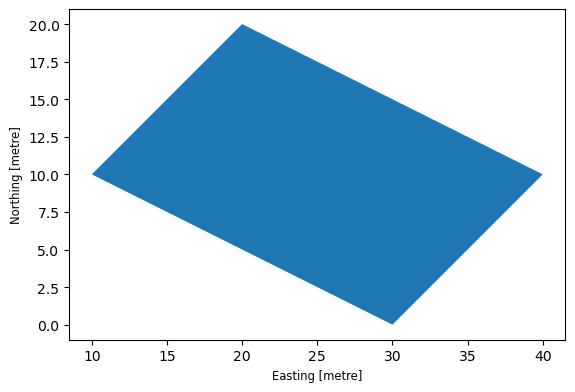

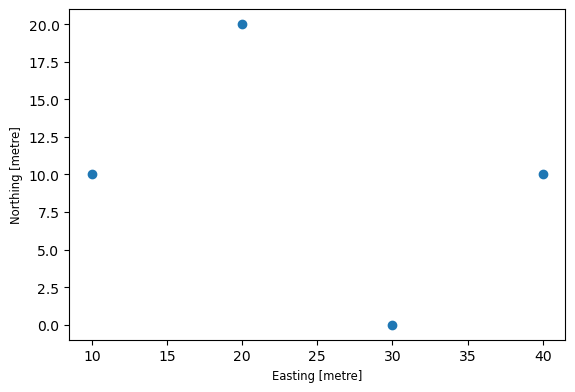

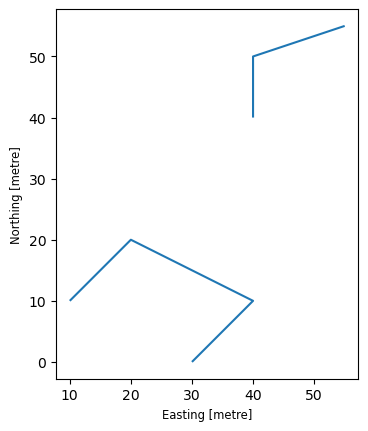

In [1]:
from shapely import Point, LineString, Polygon
import geopandas as gpd

# Obiekty punktowe możemy tworzyć po prostu podając współrzędne
p1 = Point(10, 10)
p2 = Point(20, 20)
p3 = Point(40, 10)
p4 = Point(30, 0)

print(p1)

# Z wielu obiektów punktowych możemy układać linie:
line = LineString([p1, p2, p3, p4])

print(line)

# Możemy w ten sposób tworzyć też poligony:
polygon = Polygon([p1, p2, p3, p4])

print(polygon) # Dlaczego ten print zwraca 5 współrzędnych mimo że podaliśmy tylko 4 punkty?

# Zarówno linie jak i poligony możemy też konstruować z czystych współrzędnych, nie zamkniętych w obiekt Point:
line2 = LineString([
    (40, 40),
    (40, 50),
    (55, 55)
])

print(line2)

# Możemy też stworzyć poligon bezpośrednio z linii będącej pierścieniem
ring = LineString([
    (10, 10),
    (20, 10),
    (20, 20),
    (10, 10)
])
polygon2 = Polygon(ring)

print(polygon2)

# Mając ręcznie stworzoną geometrię w shapely bez problemu możemy na jej podstawie ułożyć geodataframe:
gdf = gpd.GeoDataFrame(
    {
        "name": ["Poligon"]
    },
    geometry=[polygon],
    crs="EPSG:2180"
)

gdf.plot()

# Możemy też stworzyć obiekt który zawiera od razu wiele geometrii:
gdf2 = gpd.GeoDataFrame(
    {
        "name": ["Point1", "Point2", "Point3", "Point4"]
    },
    geometry=[p1, p2, p3, p4],
    crs="EPSG:2180"
)

gdf2.plot()

# Lub obiekt który ma tylko 1 geometrię, jest ona jednak złożona:
from shapely import MultiLineString

multiline = MultiLineString([line, line2])
gdf3 = gpd.GeoDataFrame(
    {
        "name": ["Multilinia"]
    },
    geometry=[multiline],
    crs="EPSG:2180"
)

gdf3.plot()

2. Jak tworzyć poligony z dziurami?

Możemy tworzyć poligony zawierające dziury dzięki dodatkowemu parametrowi w konstruktorze Polygon() - holes.

POLYGON ((10 10, 50 10, 50 50, 10 50, 10 10), (15 25, 25 15, 25 25, 15 30, 15 25), (15 35, 45 25, 35 45, 15 35))


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

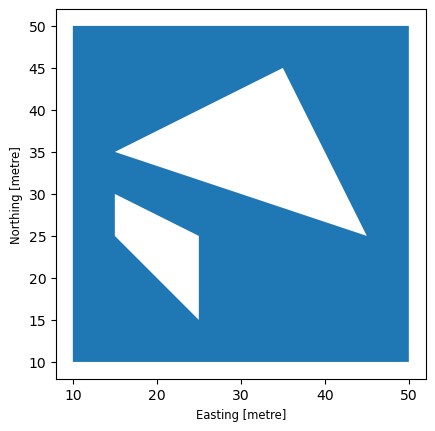

In [2]:
outer = [
    (10, 10),
    (50, 10),
    (50, 50),
    (10, 50)
]

hole1 = [
    (15, 25),
    (25, 15),
    (25, 25),
    (15, 30)
]

hole2 = [
    (15, 35),
    (45, 25),
    (35, 45)
]

polygon_with_holes = Polygon(
    outer,
    holes=[hole1, hole2]
)

print(polygon_with_holes)

gdf = gpd.GeoDataFrame(
    geometry=[polygon_with_holes],
    crs="EPSG:2180"
)

gdf.plot()

3. Jak rozbijać obiekt na nowe, mniejsze elementy?

GeoDataFrame możemy rozbijać, tworząc w tej sposób nowe elementy, na dwa sposoby: poprzez geometrię oraz poprzez atrybuty.

Dane początkowe:

   gid                    nazwa  \
0    1                     Cypr   
1  158  Wyspa Barillie-Hamilton   
2  154   Wyspa Księcia Leopolda   
3   14              Cape Breton   
4  164              Thor Island   

                                                opis legenda  \
0  Górzysta wyspa położona we wschodniej części M...   Wyspa   
1         Niezamieszkana wyspa o surowym klimacie.\n   Wyspa   
2  Ma niewielkie rozmiary, znajduje się u wybrzeż...   Wyspa   
3  Jest zbudowana ze skał krystalicznych. Część w...   Wyspa   
4  Malutka wyspa w północnej części Archipelagu A...   Wyspa   

                                              źródło   państwo       ocean  \
0  Made with Natural Earth (www.naturalearthdata....      Cypr   Atlatycki   
1  Made with Natural Earth (www.naturalearthdata....  Kanada\n   Arktyczny   
2  Made with Natural Earth (www.naturalearthdata....    Kanada   Arktyczny   
3  Made with Natural Earth (www.naturalearthdata....    Kanada  Atlantycki   
4  Made with N

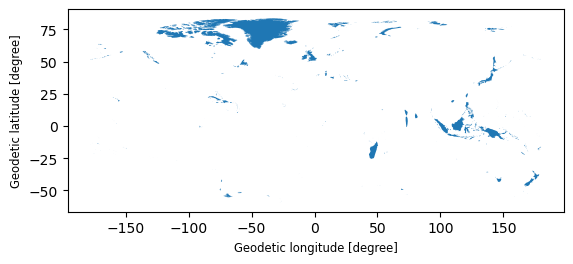

In [5]:
islands = gpd.read_file("dane/fw2.geojson")
print(islands.head())
print(islands.plot())

Rozbicie poprzez geometrię:

['MultiPolygon']
388
['Polygon']
1100
['Polygon' 'MultiPolygon']
387
['Long Island']


C:\Users\Krzysztof\AppData\Local\Temp\ipykernel_21932\1415471632.py:23: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  mean = islands.geometry.area.mean()
C:\Users\Krzysztof\AppData\Local\Temp\ipykernel_21932\1415471632.py:25: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  large_islands = islands[islands.geometry.area > mean ]
C:\Users\Krzysztof\AppData\Local\Temp\ipykernel_21932\1415471632.py:26: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  small_islands = islands[islands.geometry.area <= mean]


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

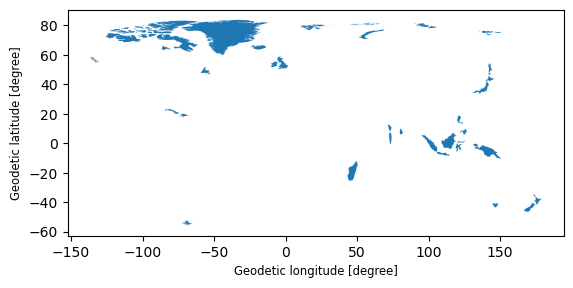

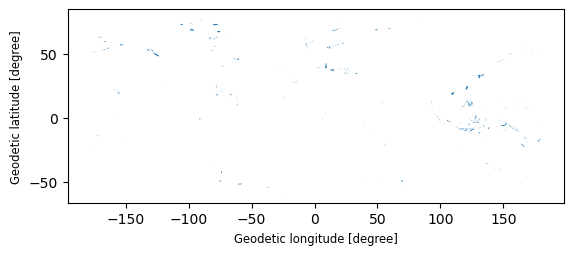

In [6]:
# Do rozbijania geometrii służy funkcja explode():
print(islands.geom_type.unique())
print(len(islands))

geoexploded_islands = islands.explode()

print(geoexploded_islands.geom_type.unique())
print(len(geoexploded_islands))

# Geometrie można potem składać funkcją dissolve(), która - w pewnym sensie - jest przeciwieństwem explode():
geodissolved_islands = geoexploded_islands.dissolve(by="nazwa")
print(geodissolved_islands.geom_type.unique())
print(len(geodissolved_islands))

# Ponieważ len() islands i geodissolved_islands się różnią, sprawmy dlaczego:
duplicate = islands.loc[
    islands["nazwa"].duplicated(),
    "nazwa"
].unique()
print(duplicate)

# Dodatkowo inną formą rozbicia jest filtrowanie gdf po warunkach nałożonych na geometrię:
mean = islands.geometry.area.mean()

large_islands = islands[islands.geometry.area > mean ]
small_islands = islands[islands.geometry.area <= mean]
# Jaka jest obecnie największa wada tej implementacji?

large_islands.plot()
small_islands.plot()

Rozbicie poprzez atrybuty:

     gid        nazwa                                               opis  \
101  343  Long Island  To wulkaniczna wyspa na Morzu Bismarcka, posia...   
383  432  Long Island  To wulkaniczna wyspa na Morzu Bismarcka, posia...   

    legenda                                             źródło  \
101   Wyspa  Made with Natural Earth (www.naturalearthdata....   
383   Wyspa  Made with Natural Earth (www.naturalearthdata....   

               państwo     ocean powierzchnia ośrodek_administracyjny waluta  \
101  Papua-Nowa Gwinea  Spokojny      500 km²                    None   kina   
383  Papua-Nowa Gwinea  Spokojny      500 km²                    None   kina   

                   język                                           geometry  
101  angielski, kreolski  MULTIPOLYGON (((147.1561 -5.44903, 147.13553 -...  
383  angielski, kreolski  MULTIPOLYGON (((-73.99893 40.69393, -73.98626 ...  


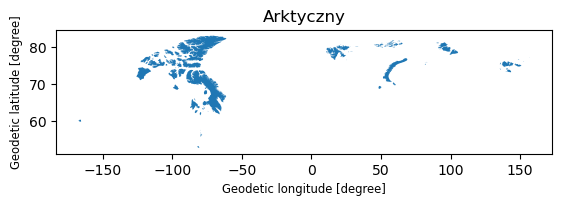

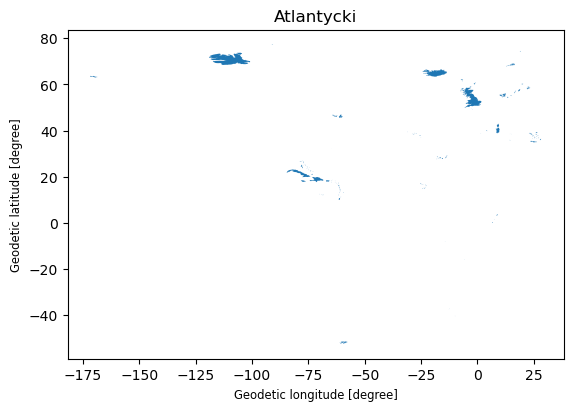

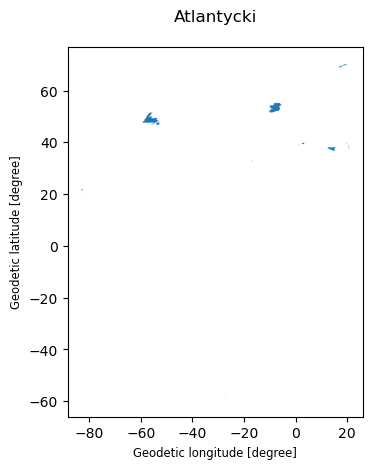

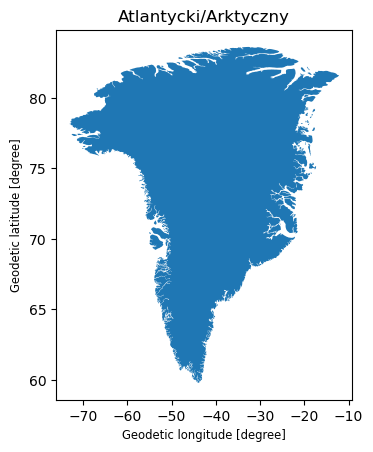

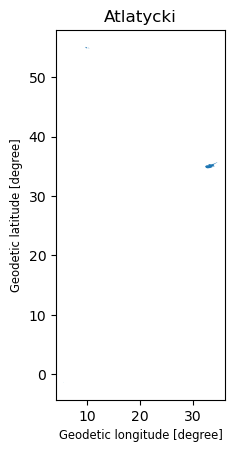

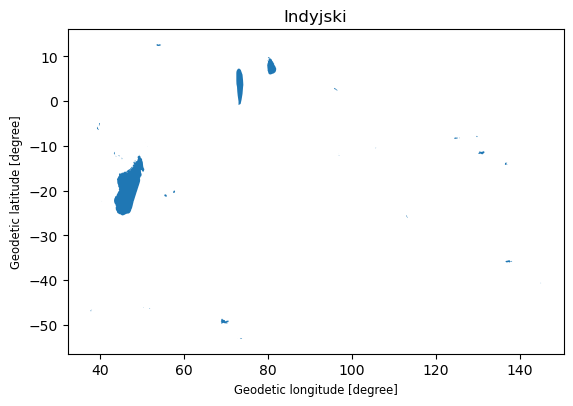

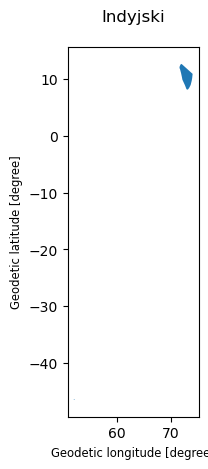

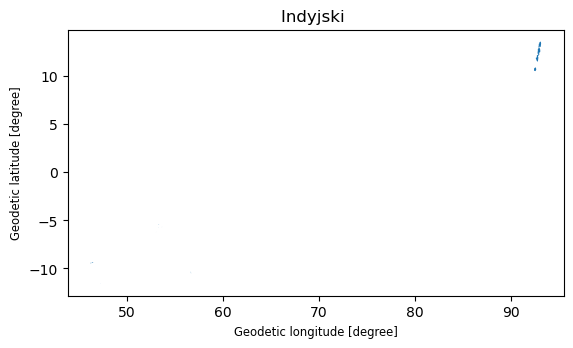

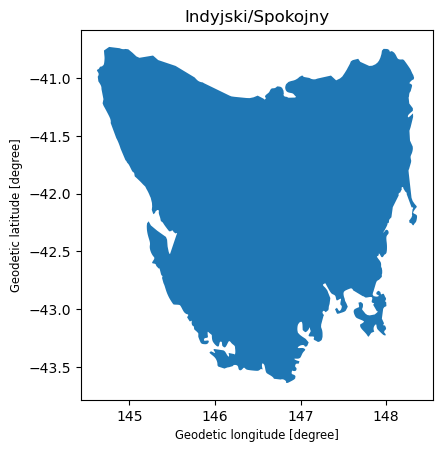

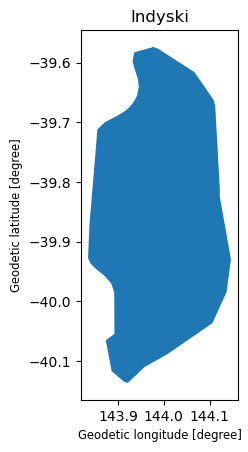

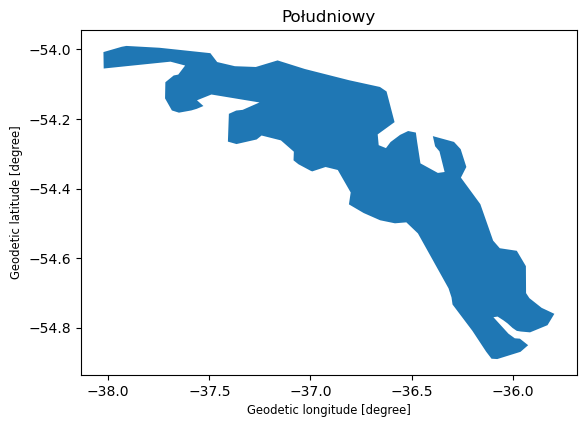

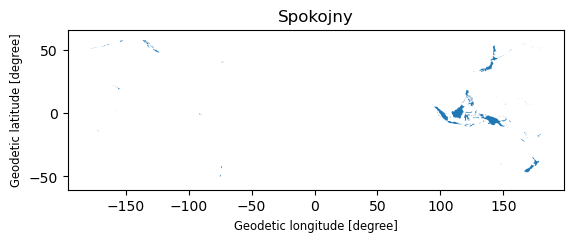

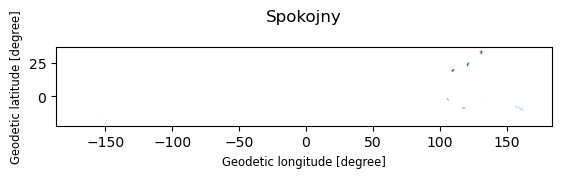

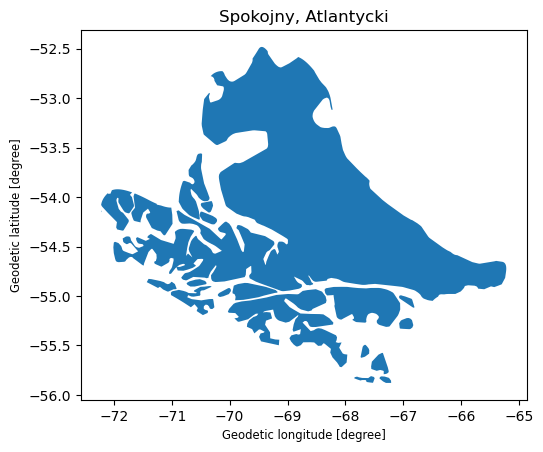

In [7]:
# Zacznijmy od przykładu stworzenia nowego gdf poprzez filtorwanie atrybutów
# Z poprzedniej sekcji dowiedzieliśmy się że mamy duplikat ze względu na nazwę. Sprawdźmy to więc dalej:

duplicate_islands = islands[islands["nazwa"] == duplicate[0]]
print(duplicate_islands.head())
# Wyjaśnij na czym polega błąd w danych i czym prawdopodobnie został spowodowany?

# Wracając do klasycznego rozbijania - tabelę atrybutów możemy grupować po wartościach, a następnie tworzyć nowe obiekty według grup:
attrgroup_islands = islands.groupby("ocean")

groups = {}
for ocean, group in attrgroup_islands:
    groups[ocean] = group

for ocean, gdf in groups.items():
    ax = gdf.plot()
    ax.set_title(ocean)
# Niektóre dane mogą wymagać czyszczenia - spróbujcie je wystandaryzować i jeszcze raz puścić grupowanie!

4. Jak wykorzystywać operacje na warstwach by tworzyć nowe geometrie?

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

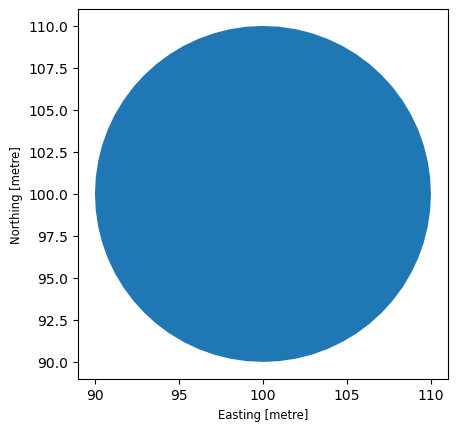

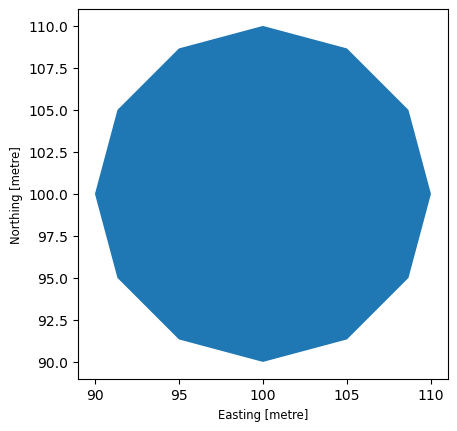

In [9]:
# Buffer:
point = gpd.GeoDataFrame(
    geometry=[Point(100,100)],
    crs="EPSG:2180"
)

buffer = point.geometry.buffer(10)
buffer.plot()

buffer2 = point.geometry.buffer(10, 3)
buffer2.plot()
# Jak interpretować drugi parametr (resolution) w buffer?

C:\Users\Krzysztof\AppData\Local\Temp\ipykernel_21932\2003495486.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroid = example_island.geometry.centroid


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

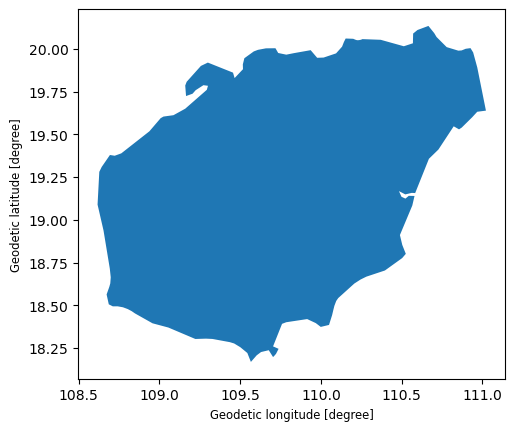

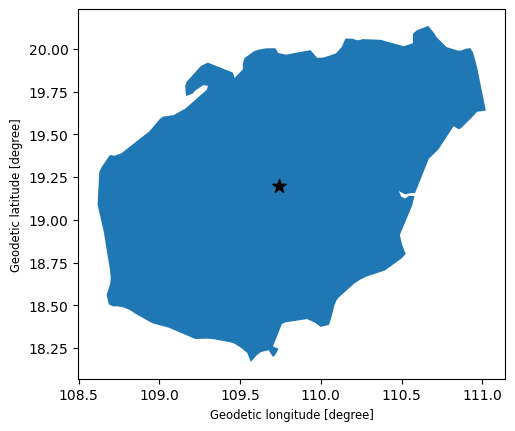

In [10]:
# Centroid:
example_island = islands.iloc[[10]]
example_island.plot()

centroid = example_island.geometry.centroid
ax = example_island.plot()
centroid.plot(ax=ax, color="black", marker="*", markersize=100)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

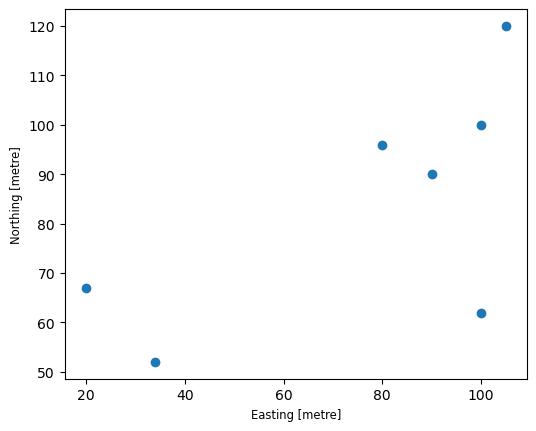

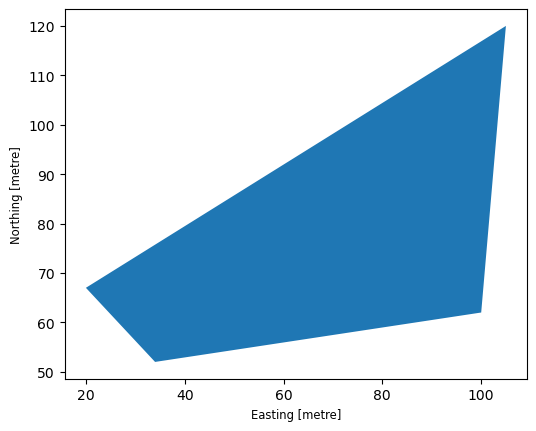

In [11]:
# Convex_hull:
from shapely import MultiPoint
many_points = gpd.GeoDataFrame(
    geometry=[
        MultiPoint([
            Point(100,100),
            Point(34, 52),
            Point(20, 67),
            Point(105, 120),
            Point(80,96),
            Point(100, 62),
            Point(90,90)
        ])
    ],
    crs="EPSG:2180"
)
many_points.plot()

convex_hull = many_points.geometry.convex_hull
# Czemu buffer był wywoływany z nawiasami () a centroid czy convex_hull już nie? Czym się różnią?

convex_hull.plot()
# Czym będzie się różnił powstały poligon od poligonu który po prostu został stworzony bezpośrednio z podanych punktów?
# Np.: Polygon([Point(100,100), Point(34, 52) ....])

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

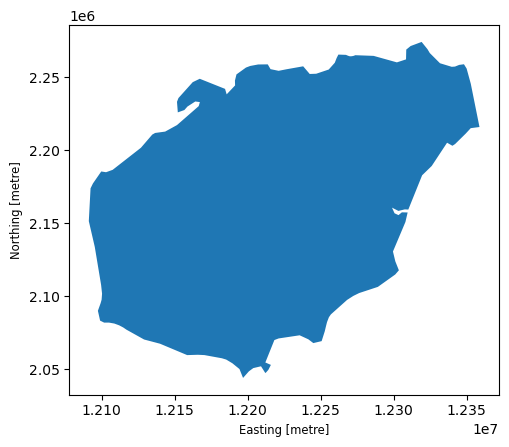

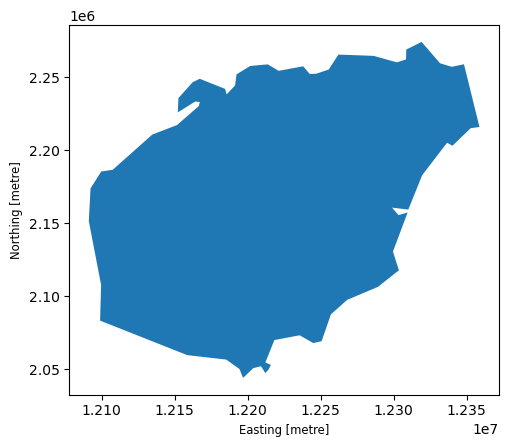

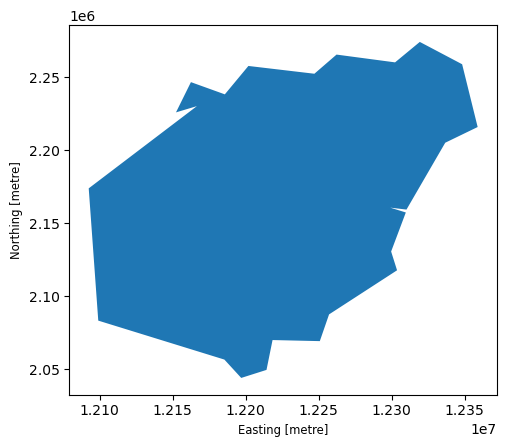

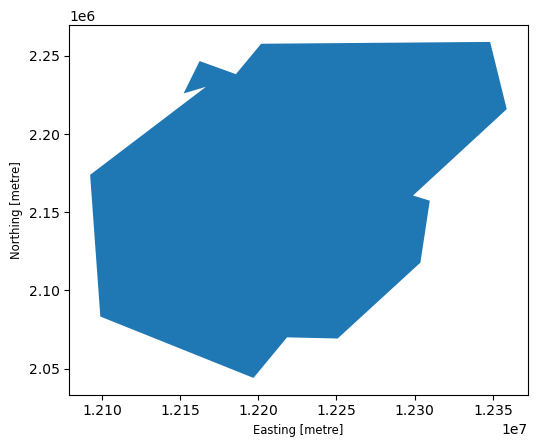

In [12]:
# Simplify
not_simplified = example_island.to_crs("3395")

simplify1 = not_simplified.simplify(2000)
simplify2 = not_simplified.simplify(5000)
simplify3 = not_simplified.simplify(10000)
# Co oznacza wartość parametru?

not_simplified.plot()
simplify1.plot()
simplify2.plot()
simplify3.plot()